# Estatística descritiva do corpus de poemas

Notebook com a análise descritiva do corpus (`data/poemas.csv`), em quatro partes:

1. **Dados e visão geral**: carga do CSV, valores faltantes, resumo global do corpus.
2. **Análise lexical**: tamanho dos poemas, frequências de palavras (total e documental), lei de Zipf, nuvem de palavras e uma prévia do tamanho do grafo de coocorrência.
3. **Metadados**: contagens por ano, técnica, local, coleção etc.
4. **Análise morfológica (spaCy)**: classes gramaticais, traços morfológicos (gênero, número, tempo, modo...), perfil morfológico por poema e, para cada classe gramatical, a nuvem de palavras e o gráfico de frequências.

**Como usar:** edite os parâmetros na primeira célula de código e rode tudo (*Run All*). Todas as tabelas (`.csv`) e figuras (`.png`) também são salvas na pasta `SAIDA`. A parte 4 precisa de spaCy; se não tiver, defina `RODAR_SPACY = False` e o restante roda normalmente.

**Glossário rápido**

| Termo | Significado |
|---|---|
| token / palavra | sequência de letras (sem pontuação nem dígitos) |
| tipo | palavra distinta; vocabulário = conjunto de tipos |
| freq | nº de ocorrências totais da palavra no corpus |
| df | frequência documental: nº de **poemas** em que a palavra aparece |
| hápax | palavra que ocorre uma única vez no corpus |
| TTR | razão tipo/ocorrência (tipos ÷ tokens) |
| UPOS | classe gramatical universal (NOUN, VERB, ADJ, ...) |

In [1]:
# %pip install pandas numpy matplotlib scipy spacy wordcloud
# !python -m spacy download pt_core_news_lg

## 0. Configuração e parâmetros

In [2]:
from __future__ import annotations

import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# ===================== PARÂMETROS (edite aqui) =====================
CSV_PATH = "../data/poemas.csv"        # caminho do CSV
SAIDA = Path("output/descritiva")   # pasta onde tabelas e figuras são salvas
TOP = 30                            # tamanho dos rankings de palavras
RODAR_SPACY = True                  # False pula a parte 4 (não precisa de spaCy)
FONTE_NUVEM = None                  # ex.: "impact.ttf" (None = fonte padrão da nuvem)
CLASSES = None                      # ex.: ["NOUN", "VERB", "ADJ"]; None = todas as classes
CLASSES_EXIBIR = ["NOUN", "VERB", "ADJ", "ADV"]   # classes mostradas aqui; as demais só são salvas (None = todas)
USAR_FORMAS = False                 # True: contar formas do texto em vez de lemas (por classe)
CLASSES_SEM_STOP = False            # True: excluir stopwords do spaCy nas análises por classe
MIN_PALAVRAS_CLASSE = 10            # mínimo de palavras para gerar as figuras de uma classe
# ===================================================================

SAIDA.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")
plt.rcParams["figure.dpi"] = 100

## Funções: carga e tokenização

- A **tokenização** aceita apenas letras (com hífen/apóstrofo internos, ex.: `sê-lo`) e converte para minúsculas. Pontuação e dígitos são ignorados.
- As **stopwords** (palavras funcionais: artigos, preposições, conjunções, pronomes...) são a lista abaixo, unida à do spaCy quando ele está instalado. Revise a lista: palavras como "mais" ou "já" podem interessar à análise.

In [3]:
# Stopwords do português (palavras funcionais).
STOPWORDS_PT = set("""
a o as os um uma uns umas de do da dos das dum duma duns dumas em no na nos nas num numa nuns numas
por pelo pela pelos pelas per para pra com sem sob sobre entre até ante após contra desde perante
e ou mas porém contudo todavia senão nem que se como quando porque pois porquanto embora conquanto
eu tu ele ela nós vós eles elas me te lhe lhes nos vos mim ti si comigo contigo consigo
meu minha meus minhas teu tua teus tuas seu sua seus suas nosso nossa nossos nossas
este esta estes estas esse essa esses essas aquele aquela aqueles aquelas isto isso aquilo
ao aos à às ali aqui aí lá cá onde
é são era eram foi foram ser sendo sido está estão estava estavam estar
há havia haver tem têm tinha tinham ter
já mais muito muita muitos muitas
""".split())

# Palavras = sequências de letras (com hífen/apóstrofo internos). Ignora pontuação e dígitos.
TOKEN_RE = re.compile(r"[^\W\d_]+(?:[-'’][^\W\d_]+)*", re.UNICODE)
SENT_RE = re.compile(r"[.!?…]+")

COLUNAS_META = ["ano", "tecnica", "local", "colecao", "local_poema", "ano_poema", "mes_poema", "dia_poema"]


def carregar(caminho: Path) -> pd.DataFrame:
    df = pd.read_csv(caminho, encoding="utf-8")
    if "estrofes" not in df.columns:
        raise SystemExit("Coluna 'estrofes' não encontrada no CSV.")
    if "id" not in df.columns:
        df["id"] = [f"poema_{i + 1:03d}" for i in range(len(df))]
    df["estrofes"] = (
        df["estrofes"].fillna("").astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
    )
    df["tokens"] = df["estrofes"].map(tokenizar)
    return df


def tokenizar(texto: str) -> list[str]:
    return [t.lower() for t in TOKEN_RE.findall(texto)]


def carregar_stopwords() -> set[str]:
    stop = set(STOPWORDS_PT)
    try:
        from spacy.lang.pt.stop_words import STOP_WORDS

        stop |= {w.lower() for w in STOP_WORDS}
    except Exception:
        pass
    return stop

## Funções: métricas e frequências

- `metricas_por_poema`: tokens, tipos, TTR, comprimento médio da palavra, sentenças e proporção de palavras funcionais, por poema.
- `tabela_frequencias`: `freq` (ocorrências totais) e `df` (nº de poemas) de cada palavra.
- `resumo_global`: números gerais do corpus (vocabulário, hápax, estatísticas do tamanho dos poemas).
- `tamanho_do_grafo`: pré-visualiza o grafo de coocorrência por poema (vértices, arestas, densidade) para cada limiar de df.
- `resumo_metadados`: valores faltantes e contagens por coluna de metadados.

In [4]:
def metricas_por_poema(df: pd.DataFrame, stop: set[str]) -> pd.DataFrame:
    linhas = []
    for pid, texto, toks in zip(df["id"], df["estrofes"], df["tokens"]):
        n = len(toks)
        tipos = len(set(toks))
        sentencas = [s for s in SENT_RE.split(texto) if s.strip()]
        conteudo = [t for t in toks if t not in stop]
        linhas.append(
            {
                "id": pid,
                "n_caracteres": len(texto),
                "n_tokens": n,
                "n_tipos": tipos,
                "ttr": tipos / n if n else np.nan,
                "comp_medio_palavra": np.mean([len(t) for t in toks]) if n else np.nan,
                "n_sentencas": len(sentencas),
                "tokens_por_sentenca": n / len(sentencas) if sentencas else np.nan,
                "n_tokens_conteudo": len(conteudo),
                "prop_funcionais": 1 - len(conteudo) / n if n else np.nan,
            }
        )
    return pd.DataFrame(linhas)


def tabela_frequencias(tokens_por_poema, stop: set[str] | None = None) -> pd.DataFrame:
    """freq = ocorrências totais; df = nº de poemas em que a palavra aparece."""
    tf, dfc = Counter(), Counter()
    for toks in tokens_por_poema:
        if stop:
            toks = [t for t in toks if t not in stop]
        tf.update(toks)
        dfc.update(set(toks))
    tab = pd.DataFrame({"palavra": list(tf), "freq": list(tf.values())})
    tab["df"] = tab["palavra"].map(dfc)
    tab = tab.sort_values(["freq", "df", "palavra"], ascending=[False, False, True]).reset_index(drop=True)
    tab["rank"] = tab.index + 1
    return tab


def resumo_global(df, por_poema, freq_total, freq_conteudo) -> pd.Series:
    n_tokens = int(por_poema["n_tokens"].sum())
    V = len(freq_total)
    hapax = int((freq_total["freq"] == 1).sum())
    return pd.Series(
        {
            "n_poemas": len(df),
            "n_poemas_vazios": int((por_poema["n_tokens"] == 0).sum()),
            "n_tokens_total": n_tokens,
            "n_tipos (vocabulário)": V,
            "ttr_global": V / n_tokens if n_tokens else np.nan,
            "hapax (freq=1)": hapax,
            "hapax / vocabulário": hapax / V if V else np.nan,
            "hapax / tokens": hapax / n_tokens if n_tokens else np.nan,
            "tipos de conteúdo (sem stopwords)": len(freq_conteudo),
            "tokens de conteúdo": int(freq_conteudo["freq"].sum()),
            "prop. tokens funcionais": 1 - freq_conteudo["freq"].sum() / n_tokens if n_tokens else np.nan,
            "tokens/poema: média": por_poema["n_tokens"].mean(),
            "tokens/poema: mediana": por_poema["n_tokens"].median(),
            "tokens/poema: desvio-padrão": por_poema["n_tokens"].std(),
            "tokens/poema: mín": por_poema["n_tokens"].min(),
            "tokens/poema: máx": por_poema["n_tokens"].max(),
            "tokens/sentença: média": por_poema["tokens_por_sentenca"].mean(),
            "comprimento médio da palavra": np.average(
                por_poema["comp_medio_palavra"].fillna(0), weights=por_poema["n_tokens"].clip(lower=1)
            ),
        },
        dtype=object,
    )


def tamanho_do_grafo(tokens_por_poema, stop: set[str], limiares=(1, 2, 3, 5)) -> pd.DataFrame:
    """Pré-visualiza o grafo de coocorrência por poema (palavras de conteúdo):
    para cada limiar de df, nº de vértices, arestas, densidade e fração de arestas de peso 1."""
    from scipy import sparse

    docs = [{t for t in toks if t not in stop} for toks in tokens_por_poema]
    vocab: dict[str, int] = {}
    for d in docs:
        for w in d:
            vocab.setdefault(w, len(vocab))
    rows, cols = [], []
    for i, d in enumerate(docs):
        for w in d:
            rows.append(i)
            cols.append(vocab[w])
    B = sparse.csr_matrix(
        (np.ones(len(rows), dtype=np.int32), (rows, cols)), shape=(len(docs), len(vocab))
    )
    df_vert = np.asarray(B.sum(axis=0)).ravel()

    res = []
    for t in limiares:
        idx = np.where(df_vert >= t)[0]
        V = len(idx)
        if V < 2:
            res.append({"df_min": t, "vertices": V, "arestas": 0, "densidade": np.nan, "frac_arestas_peso_1": np.nan})
            continue
        Bt = B[:, idx]
        W = (Bt.T @ Bt).tocoo()
        mask = W.row < W.col  # triângulo superior (sem diagonal)
        pesos = W.data[mask]
        res.append(
            {
                "df_min": t,
                "vertices": V,
                "arestas": len(pesos),
                "densidade": len(pesos) / (V * (V - 1) / 2),
                "frac_arestas_peso_1": float((pesos == 1).mean()) if len(pesos) else np.nan,
            }
        )
    return pd.DataFrame(res)


def resumo_metadados(df: pd.DataFrame, top: int = 15) -> dict[str, pd.DataFrame]:
    out = {}
    faltantes = df.drop(columns=["tokens"], errors="ignore").isna().mean().rename("prop_faltante").to_frame()
    out["faltantes"] = faltantes
    for col in COLUNAS_META:
        if col in df.columns:
            vc = df[col].value_counts(dropna=False).head(top).rename_axis(col).reset_index(name="n")
            out[col] = vc
    return out

## Funções: figuras

Cada função salva o `.png` em `SAIDA` e exibe a figura no notebook (`mostrar=False` só salva).

In [5]:
def finalizar(fig, caminho=None, mostrar=True):
    """Salva a figura (se houver caminho) e a exibe no notebook."""
    fig.tight_layout()
    if caminho is not None:
        fig.savefig(caminho, dpi=150, bbox_inches="tight")
    if mostrar:
        plt.show()
    else:
        plt.close(fig)


def fig_top_palavras(tab, titulo, caminho, top, mostrar=True):
    """Barras das `top` palavras: frequência total (azul) e nº de poemas (laranja)."""
    t = tab.head(top).iloc[::-1]
    fig, ax = plt.subplots(figsize=(7, 0.28 * len(t) + 1.5))
    ax.barh(t["palavra"], t["freq"], color="#4C72B0", label="frequência total")
    ax.barh(t["palavra"], t["df"], color="#DD8452", height=0.4, label="nº de poemas (df)")
    ax.set_title(titulo)
    ax.set_xlabel("contagem")
    ax.legend(loc="lower right")
    finalizar(fig, caminho, mostrar)


def fig_zipf(tab, caminho, mostrar=True):
    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.loglog(tab["rank"], tab["freq"], marker=".", linestyle="none", markersize=3)
    ax.set_xlabel("posto (log)")
    ax.set_ylabel("frequência (log)")
    ax.set_title("Lei de Zipf: todas as palavras")
    ax.grid(True, which="both", alpha=0.3)
    finalizar(fig, caminho, mostrar)


def fig_hist(serie, titulo, xlabel, caminho, bins=20, mostrar=True):
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.hist(serie.dropna(), bins=bins, color="#4C72B0", edgecolor="white")
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("nº de poemas")
    finalizar(fig, caminho, mostrar)


def fig_df_dist(freq_conteudo, caminho, mostrar=True):
    contagem = freq_conteudo["df"].value_counts().sort_index()
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(contagem.index[:30], contagem.values[:30], color="#55A868")
    ax.set_yscale("log")
    ax.set_xlabel("df = nº de poemas em que a palavra aparece (até 30)")
    ax.set_ylabel("nº de palavras (log)")
    ax.set_title("Distribuição da frequência documental (palavras de conteúdo)")
    finalizar(fig, caminho, mostrar)


def fig_meta_ano(df, col, caminho, mostrar=True):
    anos = pd.to_numeric(df[col], errors="coerce").dropna().astype(int)
    if anos.empty:
        return
    contagem = anos.value_counts().sort_index()
    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.bar(contagem.index, contagem.values, color="#C44E52")
    ax.set_title(f"Poemas por '{col}'")
    ax.set_xlabel(col)
    ax.set_ylabel("nº de poemas")
    finalizar(fig, caminho, mostrar)


PALETA_NUVEM = ["#F2389E", "#7660A6", "#049DD9", "#C5D932", "#F2B705"]


def nuvem_de_frequencias(contagem, caminho=None, fonte=None, seed=42, max_palavras=150,
                         titulo=None, mostrar=True):
    """Nuvem a partir de uma Series (índice = palavra, valor = frequência).
    Paleta e semente fixas: o resultado é reprodutível."""
    try:
        import random

        from wordcloud import WordCloud
    except ImportError:
        print("wordcloud não instalado (%pip install wordcloud): nuvem ignorada.")
        return None
    freq = {str(k): int(v) for k, v in contagem.items() if v > 0}
    if not freq:
        return None
    if fonte and not Path(fonte).exists():
        print(f"fonte '{fonte}' não encontrada: usando a fonte padrão da nuvem.")
        fonte = None
    rng = random.Random(seed)

    def cor(*args, **kwargs):
        return rng.choice(PALETA_NUVEM)

    wc = WordCloud(
        width=1400, height=800, background_color="white", max_words=max_palavras,
        collocations=False, font_path=fonte, prefer_horizontal=0.8, random_state=seed,
        color_func=cor,
    ).generate_from_frequencies(freq)
    if caminho is not None:
        wc.to_file(str(caminho))
    if mostrar:
        fig, ax = plt.subplots(figsize=(12, 7))
        ax.imshow(wc, interpolation="bilinear")
        ax.axis("off")
        if titulo:
            ax.set_title(titulo)
        plt.tight_layout()
        plt.show()
    return wc

## 1. Dados e visão geral

In [6]:
df = carregar(CSV_PATH)
stop = carregar_stopwords()

print(f"{len(df)} poemas; colunas: {list(df.columns.drop('tokens'))}")
display(df.drop(columns=["tokens"]).head())

111 poemas; colunas: ['id', 'pagina', 'estrofes', 'titulo', 'ano', 'tecnica', 'local', 'dimensoes', 'colecao', 'local_poema', 'dia_poema', 'mes_poema', 'ano_poema']


,id,pagina,estrofes,titulo,ano,tecnica,local,dimensoes,colecao,local_poema,dia_poema,mes_poema,ano_poema
0,poema_001,19,"Fizeram uma parada, uma parada Para o trem carregar café, Antes, estradas difíceis, só carros de bois Transitavam, levando dias e dias. Depois, uma casa aqui, outra ali. Formaram o povoado. Não Há rio, nem pedras. De tijolos caiados e telhas antigas São as construções; de taipas e Arame farpado, os divisores. Lugar arenoso no meio da terra roxa Cafeeira. Imenso céu azul circula O areal. Milhares de brancas nuvens Viajam. Caravanas luminosas Em movimento. O mais solitário, ali Deixaria de sê-lo. Toda essa fagueira Companhia. Alegre e promissor Futuro… As festas, os bailes, a banda de música Procissões e o sino repicando… Muito povo endomingado Noites enluaradas e todas as estrelas Eram mais claras do que os dias nos outros povoados.",Praça de Brodowski,1956,Desenho a nanquim bico de penpapel,"Brodowski, SP",28 × 36 cm,Coleção particular,NaN,NaN,NaN,NaN
1,poema_002,21,"Antes da luz e da água encanada, No povoado havia lamparina E cisterna; dez a quinze metros Para encontrar o líquido. Os circos traziam iluminação De carbureto. Próximos Dos elementos. Quantos vendavais e Chuvas de granizo! Moinhos de garapa, Feitos de madeira — canaviais E matas virgens com seus pássaros e Frutas. Consumiram Tudo e mais as lendas. Onde Estarão os jacus e as pacas? Os jenipapos e jatobás? As estradas cortando as Matas criavam estórias E medos. Os caminhos Também fugiram. Olhando O céu, às vezes os vejo transformados em nuvens.",Circo,1941,Desenho a guache e nanquim pincepapel,"Washington, DC","25 × 28,5 cm",Coleção particular,NaN,NaN,NaN,NaN
2,poema_003,23,"Saí das águas do mar E nasci do cafezal de Terra roxa. Passei a infância No meu povoado arenoso. Andei de bicicleta e em Cavalo em pelo. Tive medos E sonhei. Viajei no espaço. Fui à lua primeiro do que o Sputnik. Caminhei além, muito além, para Lá do paraíso. Desci de paraquedas, Atravessei o arco-íris, cheguei Nos olhos-d’água antes do sol nascer.",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,poema_004,25,Nasci e montei na garupa De muitos cavaleiros. Depois Montei sozinho em cavalo de Pé de milho. Fiz as mais Estranhas viagens e corri Na frente da chuva durante Muitos sábados. Dava poeira No trenzinho de Guaivira. Paco espanhol era meu parceiro. Vivíamos apavorados com os Temporais — pareciam odiar Aqueles lugares… Vinham ferozes contra as Sete ou oito cabanas Desarmadas.,Meninos a cavalo,1959,Gravura a água-forte e grafitpapel pardo,"Rio de Janeiro, RJ",22 × 18 cm,Coleção Sociedade dos Cem Bibliófilos do Brasil,NaN,NaN,NaN,NaN
4,poema_005,27,"Num pé de café nasci. O trenzinho passava Por entre a plantação. Deu a hora Exata. Nesse tempo os velhos Imigrantes impressionavam os recém-chegados. O tema do falatório era o lobisomem. A lua e o sol passavam longe. Mais tarde mudamos para a Rua de Cima. O sol e a lua moravam atrás de nossa Casa. Quantas vezes vi o sol parado. Éramos os primeiros a receber sua luz e calor. Em muitas ocasiões ouvi a lua cantar. Esmerava-se para aparecer nitidamente Redonda. Ficava espiando do nosso maracujazeiro. Surpreendido, vendo São Jorge à paisana, Pensei pedir-lhe o cavalo emprestado. Não me animei. A lua estava de vestido de Noiva. Os sinos começaram a badalar. As gentes acudiam, era a missa do galo. Os dos sítios do Adão e dos olhos-d’água Lá estavam desde cedo. As estrelas baixaram iluminando o lado De fora da igreja, onde se aglomeravam As gentes, os cães e os animais de montaria. O Dragão veio se chegando de chinelos…",Café,1957,Desenho a grafitpapel,"Rio de Janeiro, RJ","36,6 × 51,1 cm",Coleção particular,NaN,NaN,NaN,NaN


### Resumo global do corpus

Confira os totais: `n_tokens_total` deve ser próximo do número obtido na reunião (≈ 9.694 palavras em ≈ 111 poemas). Se destoar muito, a regra de tokenização ou a leitura do CSV (aspas, quebras de linha dentro das células) é diferente.

- **hápax / vocabulário** alto significa que a maior parte das palavras distintas aparece uma única vez, o que justifica filtrar por df ≥ 2 antes de montar o grafo.
- O **TTR** depende do tamanho do texto: poemas curtos têm TTR alto, então ele não deve ser comparado entre poemas de tamanhos muito diferentes.

In [7]:
por_poema = metricas_por_poema(df, stop)
freq_total = tabela_frequencias(df["tokens"])
freq_conteudo = tabela_frequencias(df["tokens"], stop)
resumo = resumo_global(df, por_poema, freq_total, freq_conteudo)

resumo.rename("valor").to_frame().to_csv(SAIDA / "resumo_global.csv")
por_poema.to_csv(SAIDA / "metricas_por_poema.csv", index=False)
freq_total.to_csv(SAIDA / "frequencias_todas.csv", index=False)
freq_conteudo.to_csv(SAIDA / "frequencias_conteudo.csv", index=False)

display(resumo.rename("valor").to_frame())
print("ids duplicados:", int(df["id"].duplicated().sum()))

,valor
n_poemas,111
n_poemas_vazios,0
n_tokens_total,9681
n_tipos (vocabulário),2926
ttr_global,0.302
hapax (freq=1),1917
hapax / vocabulário,0.655
hapax / tokens,0.198
tipos de conteúdo (sem stopwords),2657
tokens de conteúdo,4875


ids duplicados: 0


## 2. Análise lexical

### 2.1 Tamanho e riqueza lexical dos poemas

A mediana é mais confiável que a média se houver poucos poemas muito longos.

,count,mean,std,min,25%,50%,75%,max
n_tokens,111.000,87.216,39.236,32.000,61.000,78.000,98.000,257.000
n_tipos,111.000,69.108,25.425,29.000,51.500,66.000,79.500,167.000
ttr,111.000,0.813,0.064,0.591,0.779,0.811,0.865,0.960
comp_medio_palavra,111.000,4.756,0.342,3.925,4.546,4.739,4.995,5.629
n_sentencas,111.000,9.090,4.797,1.000,6.000,9.000,11.000,36.000
tokens_por_sentenca,111.000,12.128,12.266,5.111,7.592,8.750,10.944,93.000


Poemas mais curtos:


,id,n_tokens
55,poema_056,32
32,poema_033,33
96,poema_097,34


Poemas mais longos:


,id,n_tokens
70,poema_071,186
86,poema_087,239
109,poema_110,257


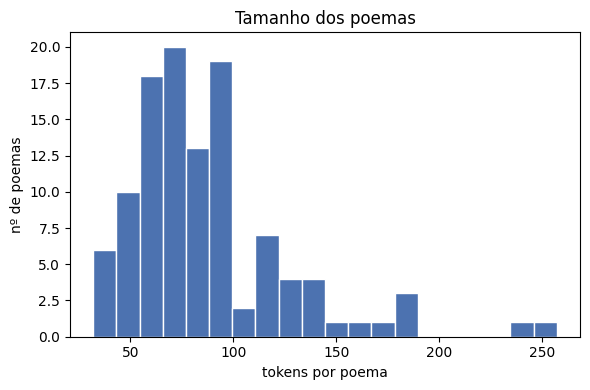

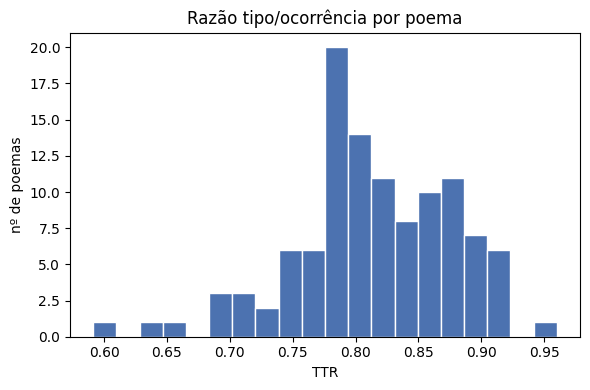

In [8]:
cols = ["n_tokens", "n_tipos", "ttr", "comp_medio_palavra", "n_sentencas", "tokens_por_sentenca"]
display(por_poema[cols].describe().T)

ordenado = por_poema.sort_values("n_tokens")
print("Poemas mais curtos:")
display(ordenado[["id", "n_tokens"]].head(3))
print("Poemas mais longos:")
display(ordenado[["id", "n_tokens"]].tail(3))

fig_hist(por_poema["n_tokens"], "Tamanho dos poemas", "tokens por poema", SAIDA / "hist_tokens.png")
fig_hist(por_poema["ttr"], "Razão tipo/ocorrência por poema", "TTR", SAIDA / "hist_ttr.png")

### 2.2 Palavras mais frequentes

Cada barra mostra a **frequência total** (azul) e, sobreposto, o **nº de poemas** em que a palavra aparece (laranja). Uma palavra com barra azul muito maior que a laranja é concentrada em poucos poemas.

Top 30 palavras (todas):


,palavra,freq,df
0,e,363,105
1,de,322,103
2,o,301,100
3,a,271,93
4,as,179,80
5,os,166,81
6,não,146,72
7,do,120,73
8,em,107,63
9,dos,89,46


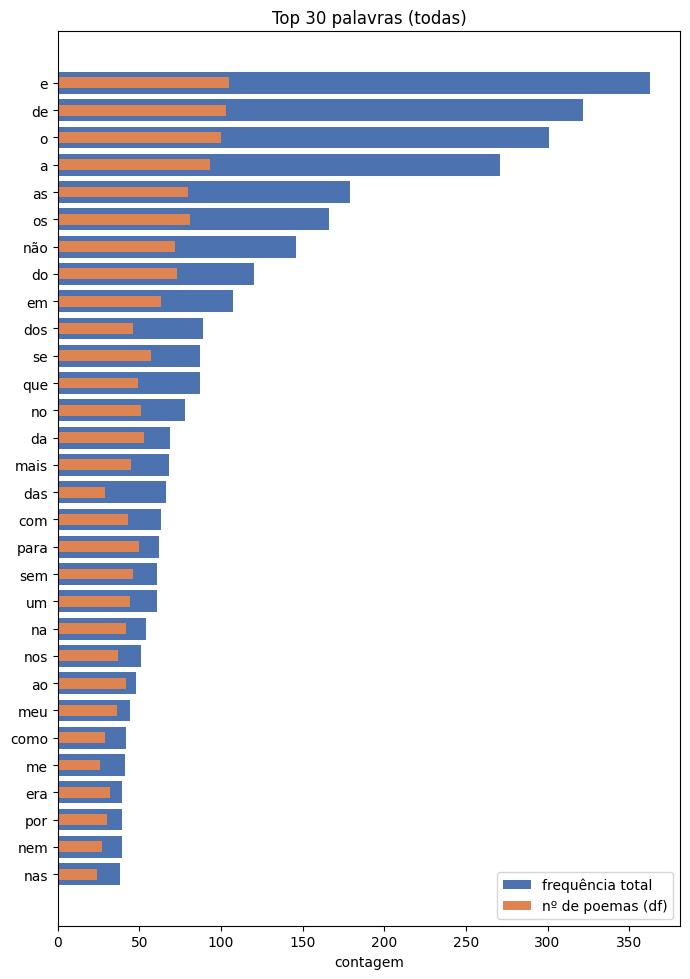

In [9]:
print(f"Top {TOP} palavras (todas):")
display(freq_total.head(TOP)[["palavra", "freq", "df"]])
fig_top_palavras(freq_total, f"Top {TOP} palavras (todas)", SAIDA / "top_palavras_todas.png", TOP)

Top 30 palavras de conteúdo (sem stopwords):


,palavra,freq,df
0,lua,36,27
1,céu,32,27
2,sol,31,25
3,vento,28,26
4,mar,23,19
5,terra,22,21
6,noite,22,20
7,flores,22,16
8,casa,21,20
9,olhos,21,20


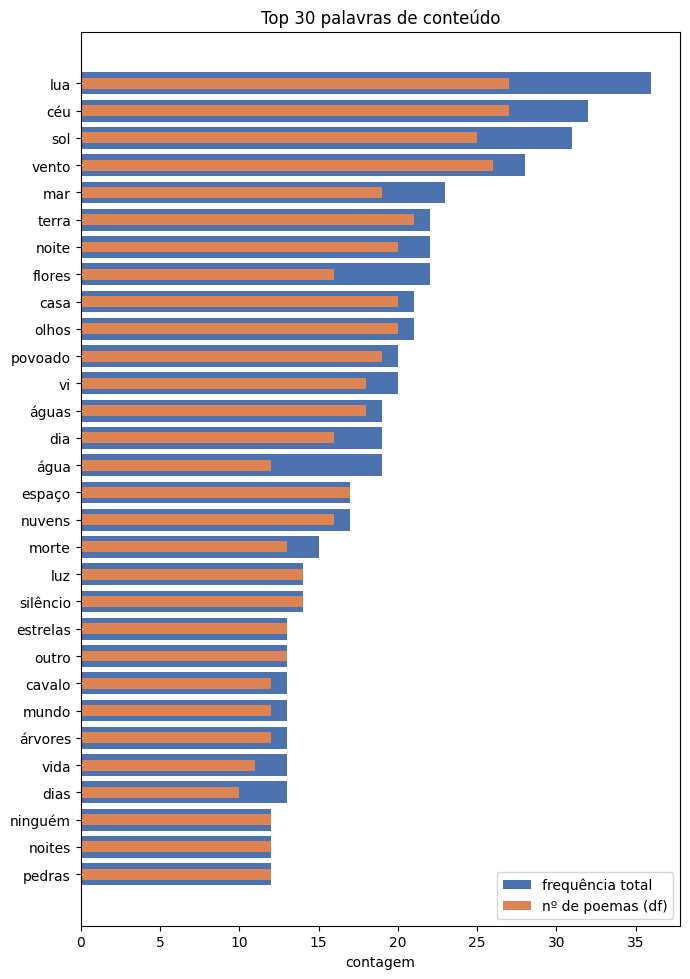

In [10]:
print(f"Top {TOP} palavras de conteúdo (sem stopwords):")
display(freq_conteudo.head(TOP)[["palavra", "freq", "df"]])
fig_top_palavras(freq_conteudo, f"Top {TOP} palavras de conteúdo", SAIDA / "top_palavras_conteudo.png", TOP)

### 2.3 Lei de Zipf e frequência documental

Em textos naturais, a frequência cai aproximadamente como uma potência do posto (reta no gráfico log-log). A distribuição do **df** mostra quantas palavras aparecem em apenas 1, 2, 3... poemas, o que orienta o limiar mínimo de df do grafo.

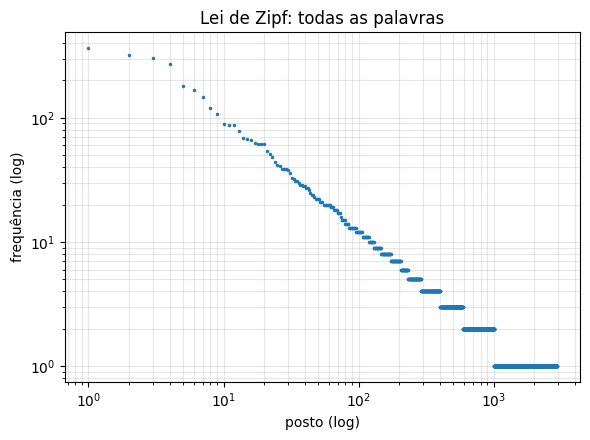

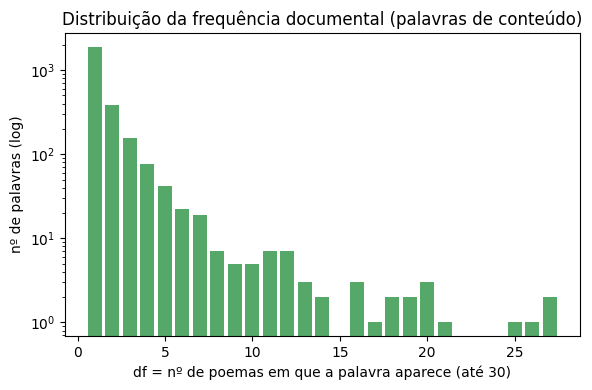

In [11]:
fig_zipf(freq_total, SAIDA / "zipf.png")
fig_df_dist(freq_conteudo, SAIDA / "dist_df.png")

### 2.4 Nuvem de palavras (palavras de conteúdo)

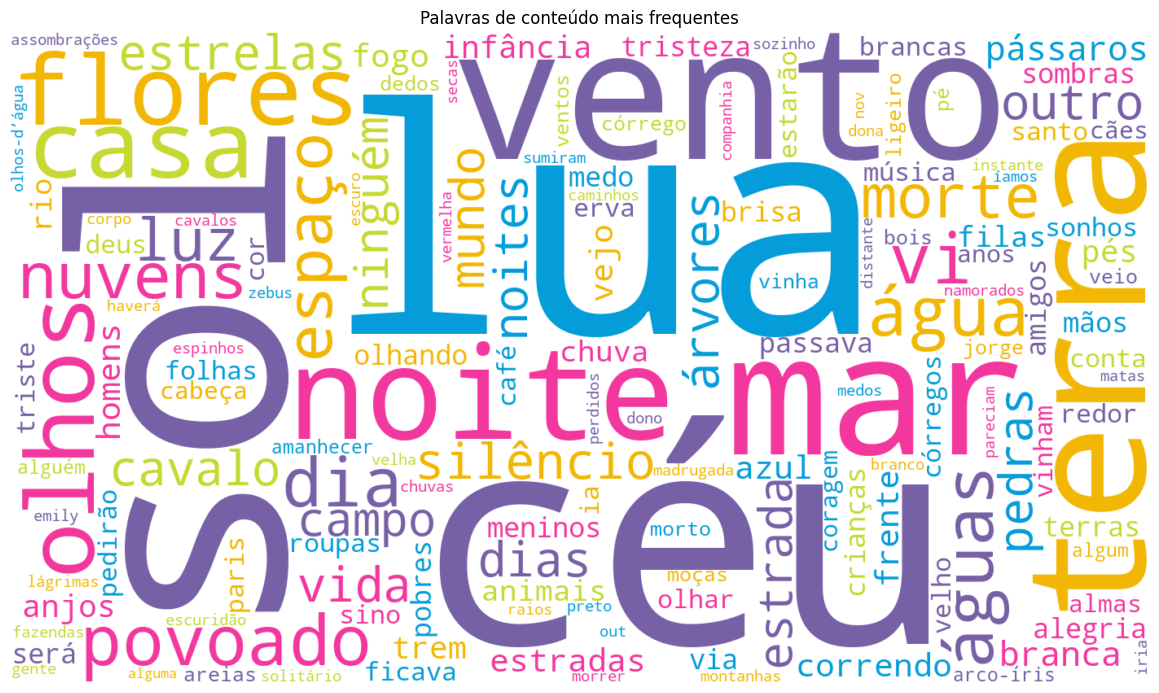

In [12]:
nuvem_de_frequencias(
    freq_conteudo.head(150).set_index("palavra")["freq"],
    SAIDA / "nuvem_palavras.png", FONTE_NUVEM,
    titulo="Palavras de conteúdo mais frequentes",
)

### 2.5 Prévia do grafo de coocorrência por poema

Para cada limiar de df (nº mínimo de poemas em que a palavra aparece): quantos vértices e arestas sobram, a densidade do grafo e a fração de arestas de peso 1 (pares que coocorrem em um único poema). Se quase todas as arestas tiverem peso 1, o grafo por poema sozinho será esparso e ruidoso.

In [13]:
grafo = tamanho_do_grafo(df["tokens"], stop)
grafo.to_csv(SAIDA / "grafo_previa.csv", index=False)
display(grafo)

,df_min,vertices,arestas,densidade,frac_arestas_peso_1
0,1,2657,106748,0.030,0.963
1,2,758,32735,0.114,0.878
2,3,369,14948,0.220,0.815
3,5,135,4359,0.482,0.636


## 3. Metadados

Proporção de valores faltantes por coluna:


,prop_faltante
id,0.000
pagina,0.000
estrofes,0.000
titulo,0.405
ano,0.405
tecnica,0.405
local,0.405
dimensoes,0.414
colecao,0.405
local_poema,0.982



Contagem por 'ano':


,ano,n
0,NaN,45
1,1943,10
2,1957,7
3,1941,6
4,1947,6
5,1956,5
6,1940,4
7,1955,4
8,1942,4
9,1944,4



Contagem por 'tecnica':


...

,ano_poema,n
0,NaN,109
1,1961.000,1
2,1958.000,1



Contagem por 'mes_poema':


,mes_poema,n
0,NaN,109
1,nov.,1
2,set.,1



Contagem por 'dia_poema':


,dia_poema,n
0,NaN,110
1,1º,1


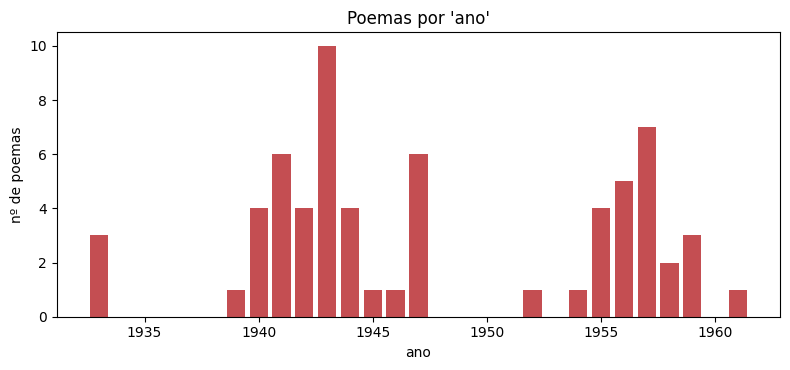

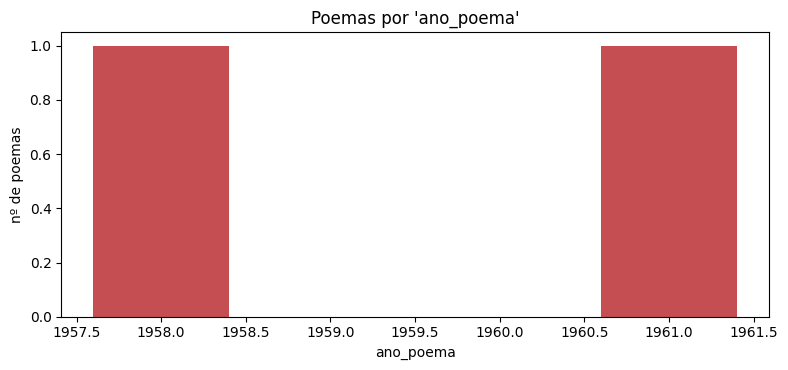

In [14]:
meta = resumo_metadados(df)
for nome, tab in meta.items():
    tab.to_csv(SAIDA / f"meta_{nome}.csv", index=nome == "faltantes")

print("Proporção de valores faltantes por coluna:")
display(meta["faltantes"])

for col in COLUNAS_META:
    if col in meta:
        print(f"\nContagem por '{col}':")
        display(meta[col])

for col in ("ano", "ano_poema"):
    if col in df.columns:
        fig_meta_ano(df, col, SAIDA / f"poemas_por_{col}.png")

## 4. Análise morfológica (spaCy)

Esta parte usa o spaCy para obter, de cada palavra, o **lema**, a **classe gramatical (UPOS)** e os **traços morfológicos** (ex.: `Gender=Masc|Number=Sing`). Instale com:

```
pip install spacy
python -m spacy download pt_core_news_lg
```

Pontos de atenção:

- As barras `/` do texto (separadores de verso) viram espaço, e a primeira letra de verso em maiúscula no meio de uma frase é rebaixada para minúscula; senão o etiquetador a confunde com nome próprio (PROPN).
- `is_stop` vem da lista de stopwords do **spaCy**, que difere da lista usada na parte 2. Os totais "sem stopwords" não batem entre as duas partes.
- O etiquetador erra mais em verso (inversões, elipses, formas arcaicas). Confira uma amostra de `tokens_spacy.csv`. O modelo `lg` é mais preciso que o `sm`.
- Palavras sem nenhum traço (preposições, advérbios, conjunções) são normais: o esquema UD não lhes atribui morfologia.

In [15]:
def texto_para_spacy(texto: str) -> str:
    """Prepara o texto para o spaCy.
    - As barras '/' (separadores de verso) viram espaço (trocar por '' colaria palavras).
    - Verso que começa em maiúscula no meio de uma frase ('... dias / Transitavam') tem a
      1ª letra rebaixada; senão o etiquetador o confunde com nome próprio (PROPN).
      Não mexe depois de . ! ? … (início real de frase)."""
    texto = re.sub(
        r"([^.!?…\s])\s*/\s*([A-ZÁÀÂÃÉÊÍÓÔÕÚÇ])",
        lambda m: m.group(1) + " " + m.group(2).lower(),
        texto,
    )
    return re.sub(r"\s+", " ", texto.replace("/", " ")).strip()


def carregar_modelo_spacy():
    try:
        import spacy
    except ImportError:
        print("  spaCy não instalado. Para POS/morfologia: pip install spacy && "
              "python -m spacy download pt_core_news_lg")
        return None
    for modelo in ("pt_core_news_lg", "pt_core_news_md", "pt_core_news_sm"):
        try:
            nlp = spacy.load(modelo, disable=["ner", "parser"])
            print(f"  modelo spaCy: {modelo}")
            return nlp
        except OSError:
            continue
    print("  Nenhum modelo pt_core_news_* encontrado: python -m spacy download pt_core_news_lg")
    return None


def tokens_spacy(df: pd.DataFrame) -> pd.DataFrame | None:
    """Uma linha por palavra (só tokens alfabéticos): id do poema, token, lema, pos (UPOS),
    morph (ex.: 'Gender=Masc|Number=Sing') e is_stop (lista de stopwords do spaCy)."""
    nlp = carregar_modelo_spacy()
    if nlp is None:
        return None
    textos = df["estrofes"].map(texto_para_spacy).tolist()
    registros = []
    for pid, doc in zip(df["id"], nlp.pipe(textos, batch_size=16)):
        for t in doc:
            if not t.is_alpha:
                continue
            registros.append(
                {
                    "id": pid,
                    "token": t.text.lower(),
                    "lema": t.lemma_.lower(),
                    "pos": t.pos_,
                    "morph": str(t.morph),
                    "is_stop": bool(t.is_stop),
                }
            )
    return pd.DataFrame(registros)


def explodir_tracos(tok: pd.DataFrame) -> pd.DataFrame:
    """Uma linha por (palavra, traço): colunas traco ('Number=Sing'), feature ('Number'), value ('Sing')."""
    m = tok.assign(traco=tok["morph"].str.split("|")).explode("traco")
    m = m[m["traco"].notna() & (m["traco"] != "")].copy()
    m[["feature", "value"]] = m["traco"].str.split("=", n=1, expand=True)
    return m

### Funções: morfologia e análise por classe gramatical

Constantes (nomes das classes, traços a examinar em cada classe) e as funções que desenham os gráficos morfológicos e geram a nuvem e as frequências de cada classe.

In [16]:
NOMES_CLASSES = {
    "NOUN": "substantivos", "VERB": "verbos", "ADJ": "adjetivos", "ADV": "advérbios",
    "PROPN": "nomes próprios", "PRON": "pronomes", "DET": "determinantes", "ADP": "preposições",
    "AUX": "verbos auxiliares", "CCONJ": "conjunções coordenativas", "SCONJ": "conjunções subordinativas",
    "NUM": "numerais", "INTJ": "interjeições", "PART": "partículas", "X": "outros",
}
PRINCIPAIS = ["NOUN", "VERB", "ADJ", "ADV", "PROPN", "PRON"]

# Quais traços olhar em cada classe (esquema Universal Dependencies)
FOCOS_MORF = [
    ("VERB", ["VerbForm", "Tense", "Mood", "Person", "Number"]),
    ("AUX", ["VerbForm", "Tense", "Mood", "Person", "Number"]),
    ("NOUN", ["Gender", "Number"]),
    ("ADJ", ["Gender", "Number", "Degree"]),
    ("PRON", ["Person", "Number", "PronType"]),
    ("DET", ["Gender", "Number", "Definite"]),
]


def fig_morf_pos(tab_pos, caminho, mostrar=True):
    t = tab_pos.sort_values("prop_todas")
    y = np.arange(len(t))
    fig, ax = plt.subplots(figsize=(7, 0.35 * len(t) + 1.5))
    ax.barh(y + 0.2, t["prop_todas"], height=0.4, color="#4C72B0", label="todas as palavras")
    ax.barh(y - 0.2, t["prop_sem_stop"], height=0.4, color="#DD8452", label="sem stopwords (spaCy)")
    ax.set_yticks(y)
    ax.set_yticklabels(t.index)
    ax.set_xlabel("proporção dos tokens")
    ax.set_title("Classes gramaticais (UPOS)")
    ax.legend(loc="lower right")
    finalizar(fig, caminho, mostrar)


def fig_morf_tracos(tab_traco, caminho, top, mostrar=True):
    t = tab_traco.sort_values("n_todas", ascending=False).head(top).iloc[::-1]
    y = np.arange(len(t))
    fig, ax = plt.subplots(figsize=(8, 0.3 * len(t) + 1.5))
    ax.barh(y + 0.2, t["n_todas"], height=0.4, color="#4C72B0", label="todas as palavras")
    ax.barh(y - 0.2, t["n_sem_stop"], height=0.4, color="#DD8452", label="sem stopwords (spaCy)")
    ax.set_yticks(y)
    ax.set_yticklabels(t.index, fontsize=8)
    ax.set_xlabel("nº de palavras com o traço")
    ax.set_title(f"Top {len(t)} traços morfológicos")
    ax.legend(loc="lower right")
    finalizar(fig, caminho, mostrar)


def fig_morf_verbos(m, caminho, mostrar=True):
    """Distribuição de VerbForm, Tense e Mood nas formas verbais (VERB + AUX)."""
    v = m[m["pos"].isin(["VERB", "AUX"])]
    feats = [f for f in ("VerbForm", "Tense", "Mood") if (v["feature"] == f).any()]
    if not feats:
        return
    fig, axes = plt.subplots(1, len(feats), figsize=(4.2 * len(feats), 3.8), squeeze=False)
    for ax, f in zip(axes[0], feats):
        c = v.loc[v["feature"] == f, "value"].value_counts()
        ax.bar(c.index, c.values / c.sum(), color="#55A868")
        ax.set_title(f"{f} (verbos e auxiliares)")
        ax.set_ylabel("proporção")
        ax.tick_params(axis="x", rotation=45)
    finalizar(fig, caminho, mostrar)


def analise_por_classe(tok, saida, top=30, fonte=None, usar_formas=False, sem_stopwords=False,
                       classes=None, min_palavras=10, exibir=None):
    """Para cada classe gramatical: tabela de frequências, barras das `top` palavras e nuvem.
    Salva tudo em <saida>/classes/ e exibe só as classes em `exibir` (None = todas).
    Retorna (dicionário classe -> tabela, tabela-resumo)."""
    col = "token" if usar_formas else "lema"
    escopo = "formas" if usar_formas else "lemas"
    base = tok[~tok["is_stop"]] if sem_stopwords else tok
    pasta = saida / "classes"
    pasta.mkdir(parents=True, exist_ok=True)

    tabelas, resumo = {}, []
    for pos in base["pos"].value_counts().index:
        if classes and pos not in classes:
            continue
        sub = base[base["pos"] == pos]
        if len(sub) < min_palavras:
            continue
        g = (
            sub.groupby(col)
            .agg(freq=("token", "size"), df=("id", "nunique"))
            .reset_index()
            .rename(columns={col: "palavra"})
            .sort_values(["freq", "df", "palavra"], ascending=[False, False, True])
            .reset_index(drop=True)
        )
        g["rank"] = g.index + 1
        g.to_csv(pasta / f"freq_{pos}.csv", index=False)
        tabelas[pos] = g

        nome = NOMES_CLASSES.get(pos, pos)
        mostrar = exibir is None or pos in exibir
        if mostrar:
            print(f"\n{'=' * 60}\n{nome} ({pos}): {len(sub)} palavras, {len(g)} {escopo} distintos\n{'=' * 60}")
        fig_top_palavras(g, f"{nome} ({pos}): top {min(top, len(g))} {escopo}",
                         pasta / f"freq_{pos}.png", top, mostrar=mostrar)
        nuvem_de_frequencias(g.set_index("palavra")["freq"], pasta / f"nuvem_{pos}.png", fonte,
                             max_palavras=100, titulo=f"{nome} ({pos})", mostrar=mostrar)
        resumo.append({
            "classe": pos, "nome": nome, "palavras": len(sub), f"{escopo}_distintos": len(g),
            "mais_frequentes": ", ".join(f"{w} ({f})" for w, f in zip(g["palavra"].head(5), g["freq"].head(5))),
        })

    # painel com as classes principais, para slide
    pan = [p for p in PRINCIPAIS if p in tabelas]
    if pan:
        n_col = 3 if len(pan) > 4 else 2
        n_lin = int(np.ceil(len(pan) / n_col))
        fig, axes = plt.subplots(n_lin, n_col, figsize=(5.2 * n_col, 4.2 * n_lin), squeeze=False)
        for ax, pos in zip(axes.ravel(), pan):
            t = tabelas[pos].head(10).iloc[::-1]
            ax.barh(t["palavra"], t["freq"], color="#4C72B0")
            ax.set_title(f"{NOMES_CLASSES.get(pos, pos)} ({pos})", fontsize=10)
            ax.tick_params(labelsize=8)
        for ax in axes.ravel()[len(pan):]:
            ax.axis("off")
        fig.suptitle(f"Top 10 {escopo} por classe gramatical")
        print(f"\n{'=' * 60}\nPainel das classes principais\n{'=' * 60}")
        finalizar(fig, saida / "classes_painel_frequencias.png")
    return tabelas, pd.DataFrame(resumo)

In [17]:
tok = tokens_spacy(df) if RODAR_SPACY else None

if tok is not None:
    tok.to_csv(SAIDA / "tokens_spacy.csv", index=False)
    print(f"{len(tok)} palavras alfabéticas; {int((~tok['is_stop']).sum())} sem stopwords (spaCy); "
          f"{int((tok['morph'] == '').sum())} sem nenhum traço morfológico.")
    display(tok.head(15))

  modelo spaCy: pt_core_news_lg
9497 palavras alfabéticas; 4807 sem stopwords (spaCy); 1791 sem nenhum traço morfológico.


,id,token,lema,pos,morph,is_stop
0,poema_001,fizeram,fizeram,VERB,Mood=Ind|Number=Plur|Person=3|Tense=Past|VerbForm=Fin,False
1,poema_001,uma,um,DET,Definite=Ind|Gender=Fem|Number=Sing|PronType=Art,True
2,poema_001,parada,parada,NOUN,Gender=Fem|Number=Sing,False
3,poema_001,uma,um,DET,Definite=Ind|Gender=Fem|Number=Sing|PronType=Art,True
4,poema_001,parada,parada,NOUN,Gender=Fem|Number=Sing,False
5,poema_001,para,para,ADP,,True
6,poema_001,o,o,DET,Definite=Def|Gender=Masc|Number=Sing|PronType=Art,True
7,poema_001,trem,trem,NOUN,Gender=Masc|Number=Sing,False
8,poema_001,carregar,carregar,VERB,VerbForm=Inf,False
9,poema_001,café,café,NOUN,Gender=Masc|Number=Sing,False


### 4.1 Classes gramaticais (UPOS)

Proporção de cada classe entre todas as palavras e entre as palavras de conteúdo (sem stopwords do spaCy).

,n_todas,n_sem_stop,prop_todas,prop_sem_stop
pos,,,,
NOUN,2427,2315,0.256,0.482
VERB,1485,1366,0.156,0.284
ADP,1405,17,0.148,0.004
DET,1269,40,0.134,0.008
ADV,617,45,0.065,0.009
ADJ,496,460,0.052,0.096
PRON,465,77,0.049,0.016
CCONJ,440,0,0.046,0.000
PROPN,427,403,0.045,0.084


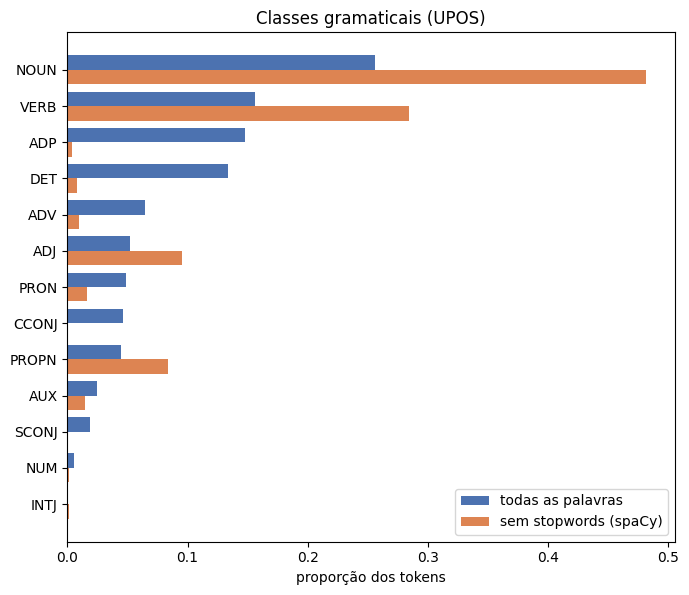

In [18]:
if tok is None:
    print("spaCy indisponível (RODAR_SPACY = False, ou spaCy/modelo não instalado): pule esta seção.")
else:
    p_todas = tok["pos"].value_counts()
    p_sem = tok.loc[~tok["is_stop"], "pos"].value_counts()
    tab_pos = pd.DataFrame({"n_todas": p_todas, "n_sem_stop": p_sem}).fillna(0).astype(int)
    tab_pos["prop_todas"] = tab_pos["n_todas"] / tab_pos["n_todas"].sum()
    tab_pos["prop_sem_stop"] = tab_pos["n_sem_stop"] / max(tab_pos["n_sem_stop"].sum(), 1)
    tab_pos = tab_pos.sort_values("n_todas", ascending=False)
    tab_pos.rename_axis("pos").to_csv(SAIDA / "morf_pos.csv")
    display(tab_pos)

    fig_morf_pos(tab_pos, SAIDA / "morf_pos.png")

### 4.2 Traços morfológicos

Contagem dos traços `Feature=Valor`. A coluna `n_sem_stop` conta só palavras que não são stopwords (spaCy), como no código usado pelo grupo. A coluna `prop_palavras` é a fração das palavras do corpus que têm o traço.

Atenção: a contagem agregada mistura classes (um `Number=Sing` de substantivo e um de verbo contam igual); por isso a seção 4.3 detalha por classe gramatical.

,n_todas,n_sem_stop,prop_palavras
traco,,,
Number=Sing,4570,2785,0.481
Gender=Masc,3308,1858,0.348
Number=Plur,2606,1669,0.274
Gender=Fem,2523,1558,0.266
PronType=Art,1604,3,0.169
Definite=Def,1507,3,0.159
VerbForm=Fin,1165,930,0.123
Mood=Ind,1084,862,0.114
Person=3,1028,727,0.108


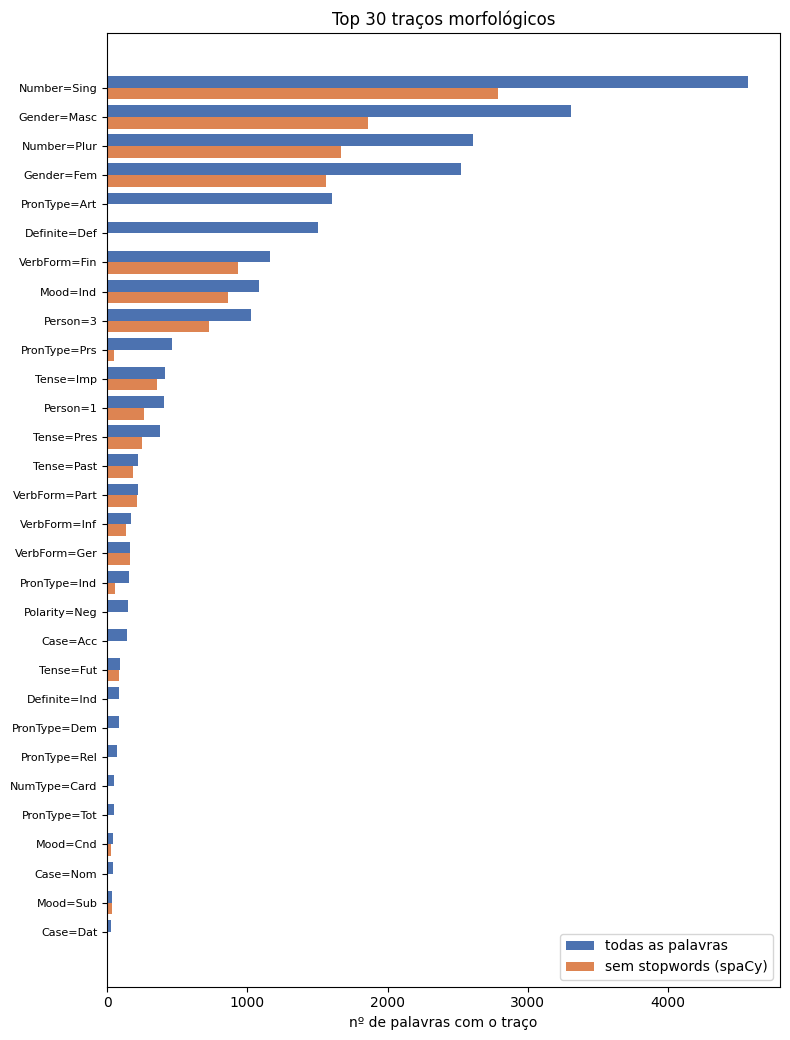

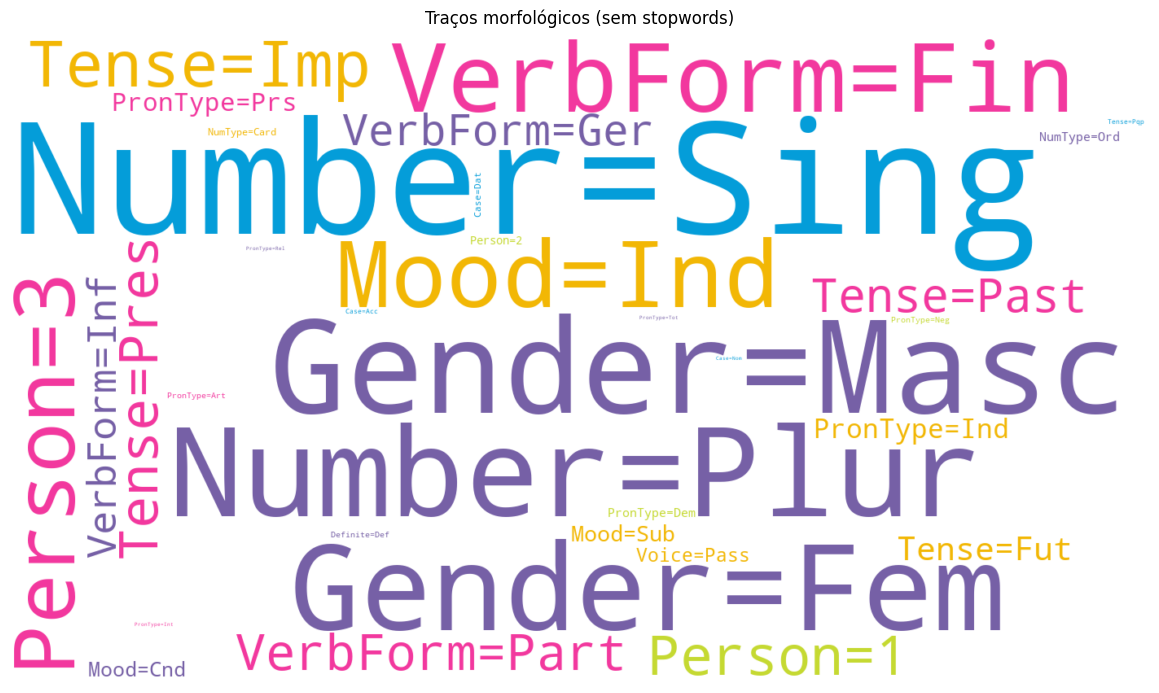

In [19]:
if tok is None:
    print("spaCy indisponível (RODAR_SPACY = False, ou spaCy/modelo não instalado): pule esta seção.")
else:
    m = explodir_tracos(tok)

    c_todas = m["traco"].value_counts()
    c_sem = m.loc[~m["is_stop"], "traco"].value_counts()
    tab_traco = pd.DataFrame({"n_todas": c_todas, "n_sem_stop": c_sem}).fillna(0).astype(int)
    tab_traco["prop_palavras"] = tab_traco["n_todas"] / len(tok)
    tab_traco = tab_traco.sort_values("n_todas", ascending=False)
    tab_traco.rename_axis("traco").to_csv(SAIDA / "morf_tracos.csv")

    display(tab_traco.head(TOP))
    fig_morf_tracos(tab_traco, SAIDA / "morf_tracos_top.png", TOP)
    nuvem_de_frequencias(
        tab_traco["n_sem_stop"], SAIDA / "wordcloud_morfologia_poemas.png", FONTE_NUVEM,
        titulo="Traços morfológicos (sem stopwords)",
    )

### 4.3 Valores de cada traço, e traços por classe gramatical

- **Valores por traço**: dentro de cada traço, a proporção de cada valor (ex.: `Tense`: Pres, Past, Imp, Fut...).
- **Traços por classe**: a mesma distribuição, mas dentro de cada classe (tempo e modo entre os verbos, gênero e número entre substantivos e adjetivos). É a leitura mais interpretável.

In [20]:
if tok is None:
    print("spaCy indisponível (RODAR_SPACY = False, ou spaCy/modelo não instalado): pule esta seção.")
else:
    por_feat = m.groupby(["feature", "value"]).size().rename("n").reset_index()
    por_feat["prop_no_traco"] = por_feat["n"] / por_feat.groupby("feature")["n"].transform("sum")
    por_feat = por_feat.sort_values(["feature", "n"], ascending=[True, False])
    por_feat.to_csv(SAIDA / "morf_valores_por_traco.csv", index=False)

    por_pos = m.groupby(["pos", "feature", "value"]).size().rename("n").reset_index()
    por_pos["prop_na_classe"] = por_pos["n"] / por_pos.groupby(["pos", "feature"])["n"].transform("sum")
    por_pos = por_pos.sort_values(["pos", "feature", "n"], ascending=[True, True, False])
    por_pos.to_csv(SAIDA / "morf_traco_por_classe.csv", index=False)

    linhas = []
    for pos, feats in FOCOS_MORF:
        for f in feats:
            sub = por_pos[(por_pos["pos"] == pos) & (por_pos["feature"] == f)]
            if sub.empty:
                continue
            linhas.append({
                "classe": pos, "traço": f, "n": int(sub["n"].sum()),
                "distribuição": ", ".join(f"{v} {p:.0%}" for v, p in zip(sub["value"], sub["prop_na_classe"])),
            })
    tab_focos = pd.DataFrame(linhas)
    print("Traços por classe gramatical (proporção dentro de classe e traço):")
    display(tab_focos)

    print("\nValores de cada traço (todas as classes):")
    display(por_feat)

Traços por classe gramatical (proporção dentro de classe e traço):


,classe,traço,n,distribuição
0,VERB,VerbForm,1485,"Fin 63%, Part 15%, Ger 11%, Inf 11%"
1,VERB,Tense,903,"Imp 37%, Pres 33%, Past 22%, Fut 8%, Pqp 0%"
2,VERB,Mood,942,"Ind 94%, Sub 4%, Cnd 2%"
3,VERB,Person,957,"3 75%, 1 25%, 2 0%"
4,VERB,Number,1167,"Sing 60%, Plur 40%"
5,AUX,VerbForm,230,"Fin 97%, Inf 3%"
6,AUX,Tense,200,"Imp 41%, Pres 40%, Past 10%, Fut 9%"
7,AUX,Mood,223,"Ind 88%, Cnd 10%, Sub 2%"
8,AUX,Person,225,"3 85%, 1 15%"
9,AUX,Number,225,"Sing 67%, Plur 33%"



Valores de cada traço (todas as classes):


,feature,value,n,prop_no_traco
0,Case,Acc,140,0.667
2,Case,Nom,42,0.200
1,Case,Dat,28,0.133
3,Definite,Def,1507,0.945
4,Definite,Ind,87,0.055
6,Gender,Masc,3308,0.567
5,Gender,Fem,2523,0.433
8,Mood,Ind,1084,0.930
7,Mood,Cnd,44,0.038
9,Mood,Sub,37,0.032


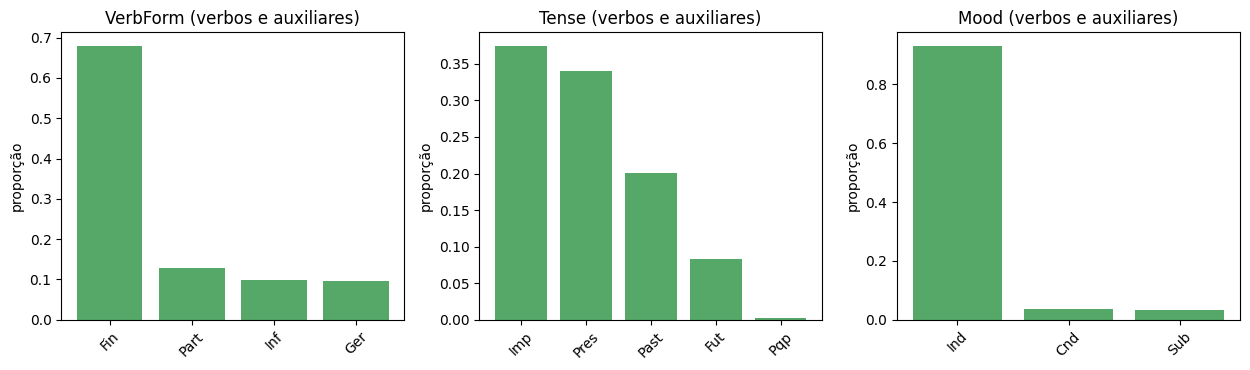

In [ ]:
if tok is None:
    print("spaCy indisponível (RODAR_SPACY = False, ou spaCy/modelo não instalado): pule esta seção.")
else:
    fig_morf_verbos(m, SAIDA / "morf_verbos.png")

### 4.4 Perfil morfológico por poema

Para cada poema: proporção de cada classe gramatical (`prop_*`) e proporção de cada tempo verbal entre os verbos (`tempo_*`; `NaN` onde o poema não tem verbo com tempo marcado). É a "assinatura" morfológica do poema e pode alimentar uma comparação ou clusterização depois.

In [ ]:
if tok is None:
    print("spaCy indisponível (RODAR_SPACY = False, ou spaCy/modelo não instalado): pule esta seção.")
else:
    prof_pos = pd.crosstab(tok["id"], tok["pos"], normalize="index").add_prefix("prop_")
    verbos = m[m["pos"].isin(["VERB", "AUX"]) & (m["feature"] == "Tense")]
    prof_tempo = pd.crosstab(verbos["id"], verbos["value"], normalize="index").add_prefix("tempo_")
    perfil = pd.DataFrame(index=df["id"]).join(prof_pos).join(prof_tempo)
    perfil.insert(0, "n_palavras", tok.groupby("id").size().reindex(perfil.index).fillna(0).astype(int))
    perfil.rename_axis("id").to_csv(SAIDA / "morf_perfil_por_poema.csv")
    display(perfil.head(10))

,n_palavras,prop_ADJ,prop_ADP,prop_ADV,prop_AUX,prop_CCONJ,prop_DET,prop_INTJ,prop_NOUN,prop_NUM,prop_PRON,prop_PROPN,prop_SCONJ,prop_VERB,tempo_Fut,tempo_Imp,tempo_Past,tempo_Pqp,tempo_Pres
id,,,,,,,,,,,,,,,,,,,
poema_001,121,0.091,0.091,0.083,0.017,0.058,0.165,0.000,0.314,0.000,0.008,0.058,0.008,0.107,0.000,0.167,0.167,0.000,0.667
poema_002,91,0.033,0.132,0.044,0.000,0.099,0.132,0.000,0.330,0.022,0.022,0.055,0.011,0.121,0.167,0.500,0.167,0.000,0.167
poema_003,61,0.049,0.295,0.098,0.000,0.049,0.066,0.000,0.246,0.000,0.016,0.016,0.000,0.164,0.000,0.000,1.000,0.000,0.000
poema_004,60,0.067,0.200,0.033,0.017,0.050,0.117,0.000,0.233,0.017,0.000,0.100,0.000,0.167,0.000,0.444,0.444,0.000,0.111
poema_005,159,0.006,0.151,0.057,0.025,0.031,0.195,0.000,0.252,0.000,0.019,0.057,0.025,0.182,0.000,0.571,0.381,0.000,0.048
poema_006,76,0.053,0.092,0.105,0.000,0.053,0.132,0.000,0.250,0.000,0.039,0.013,0.026,0.237,0.286,0.000,0.000,0.000,0.714
poema_007,103,0.068,0.155,0.019,0.039,0.049,0.175,0.000,0.311,0.010,0.000,0.087,0.010,0.078,0.125,0.625,0.000,0.000,0.250
poema_008,93,0.054,0.151,0.108,0.022,0.108,0.108,0.000,0.258,0.000,0.054,0.022,0.011,0.108,0.000,0.300,0.200,0.000,0.500
poema_009,81,0.025,0.210,0.037,0.000,0.111,0.074,0.000,0.321,0.012,0.025,0.037,0.012,0.136,0.000,0.778,0.111,0.000,0.111


### 4.5 Nuvem de palavras e frequências de cada classe gramatical

Para cada classe (substantivos, verbos, adjetivos, advérbios, pronomes...), são gerados:

- `classes/nuvem_<CLASSE>.png`: a nuvem de palavras da classe;
- `classes/freq_<CLASSE>.png`: o gráfico de barras das `TOP` palavras mais frequentes (frequência total e nº de poemas);
- `classes/freq_<CLASSE>.csv`: a tabela completa de frequências da classe;
- `classes_painel_frequencias.png`: painel com o top 10 das classes principais.

Por padrão contam-se **lemas** e **incluem-se stopwords** (senão classes como pronomes e preposições ficariam vazias). Mude `USAR_FORMAS`, `CLASSES_SEM_STOP`, `CLASSES` e `CLASSES_EXIBIR` na célula de parâmetros. Todas as classes são salvas em disco; só as de `CLASSES_EXIBIR` são mostradas aqui.


substantivos (NOUN): 2427 palavras, 913 lemas distintos


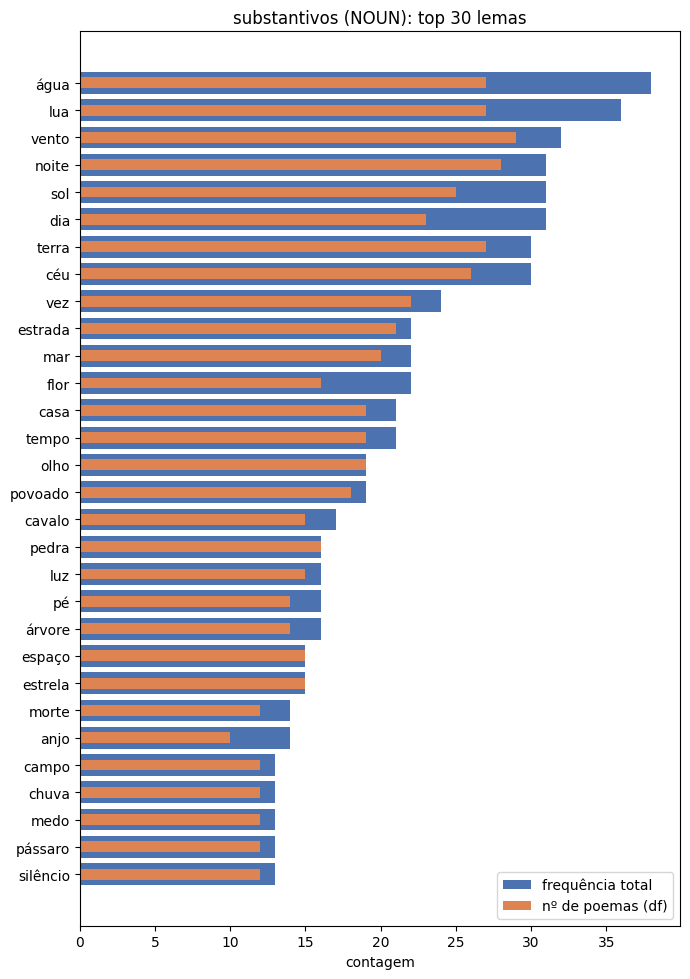

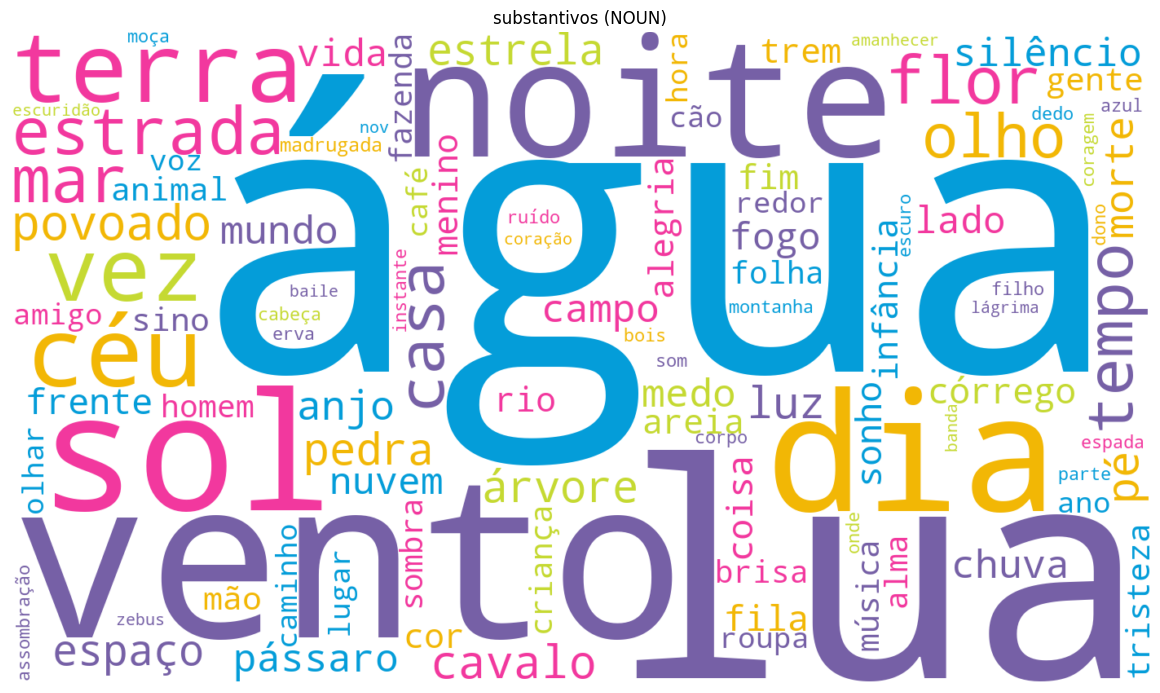


verbos (VERB): 1485 palavras, 706 lemas distintos


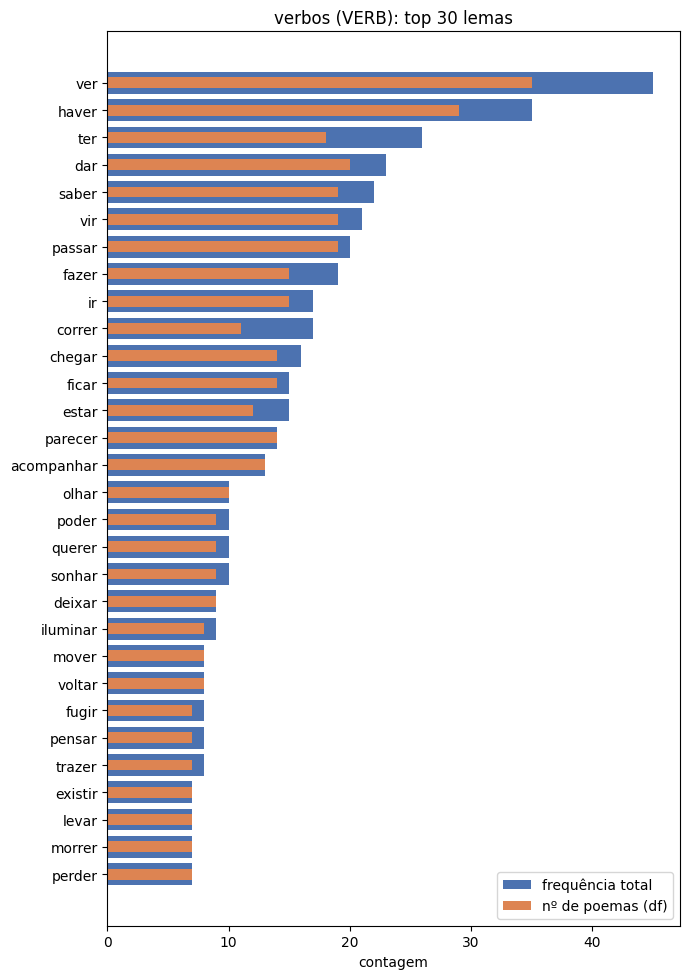

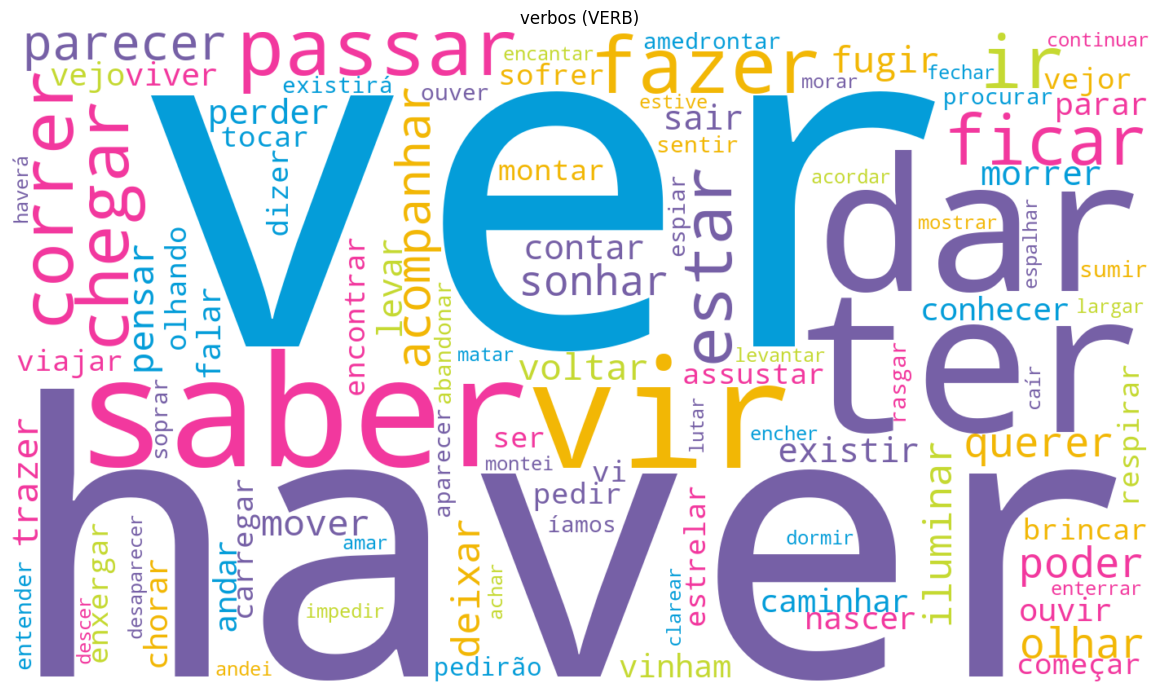


advérbios (ADV): 617 palavras, 79 lemas distintos


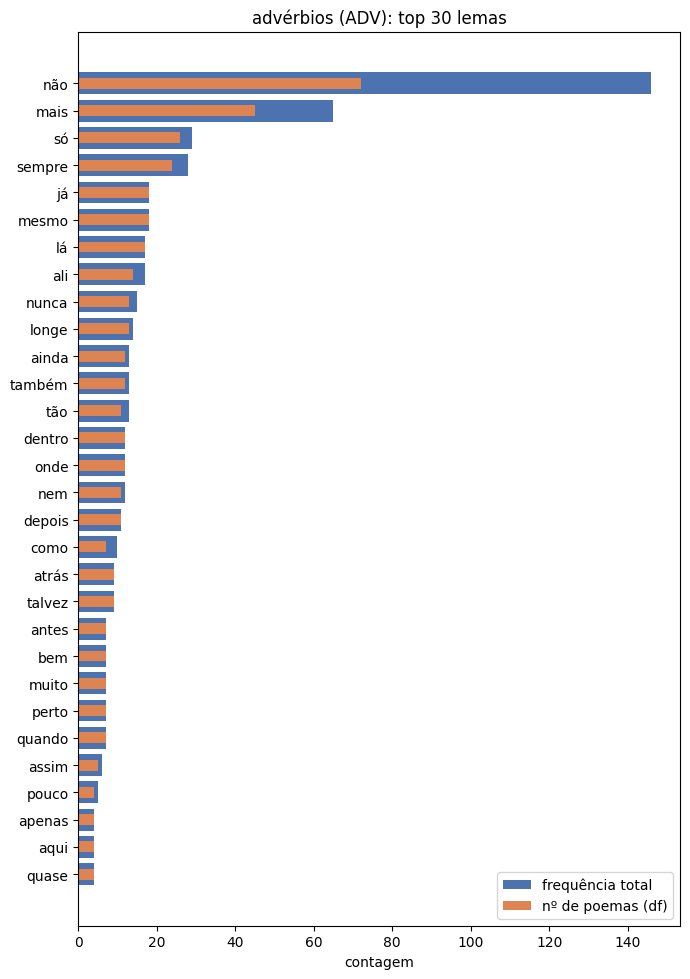

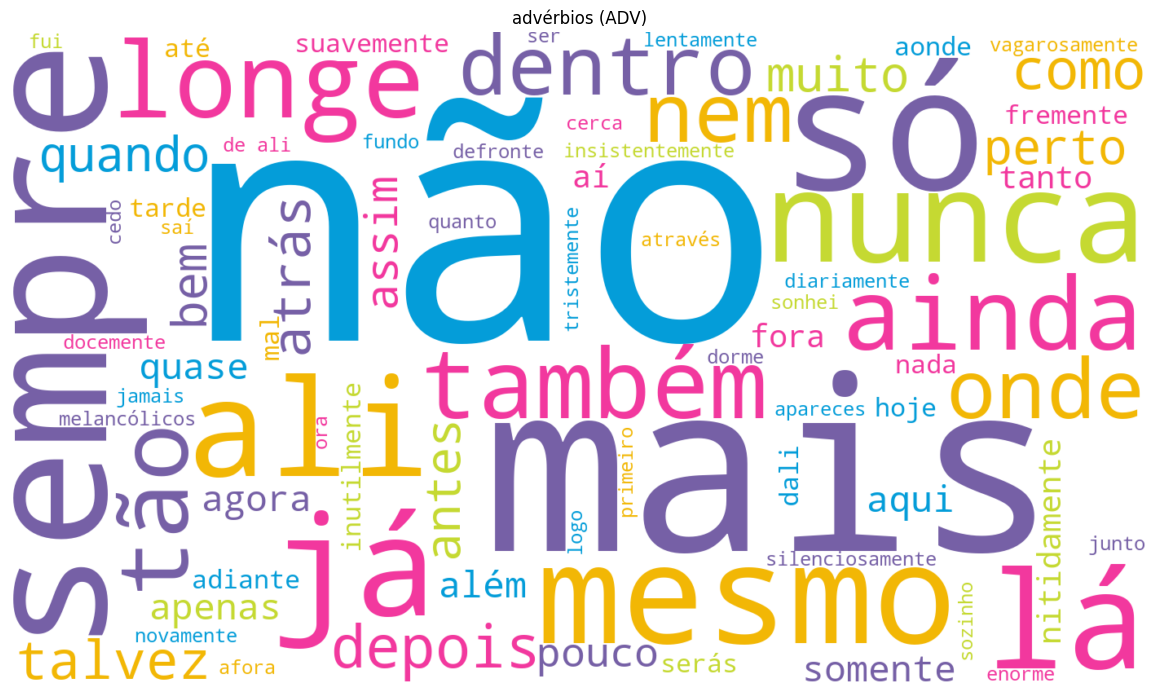


adjetivos (ADJ): 496 palavras, 259 lemas distintos


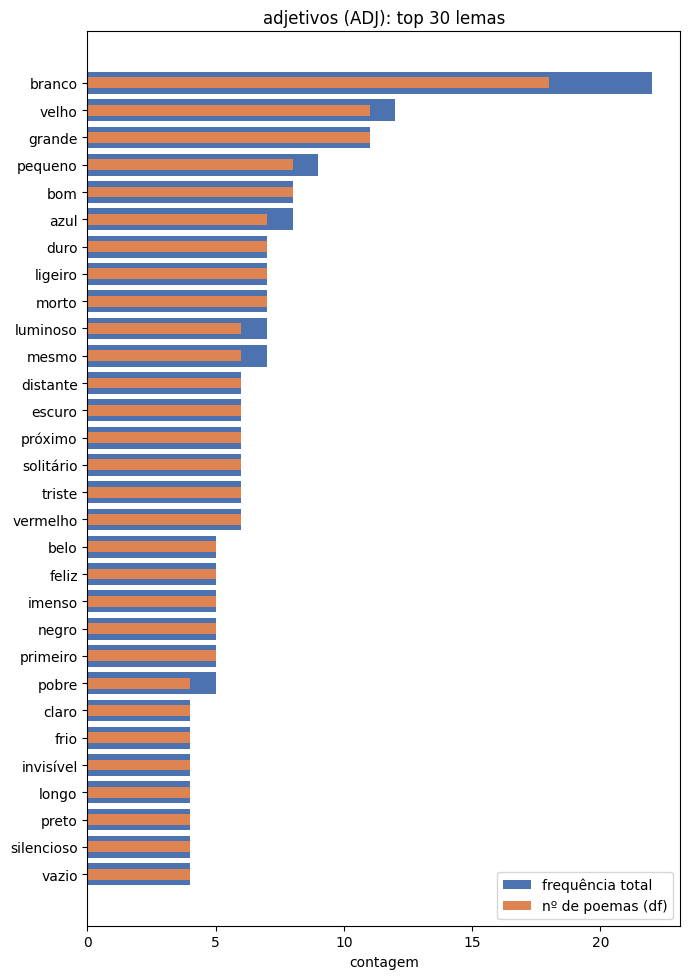

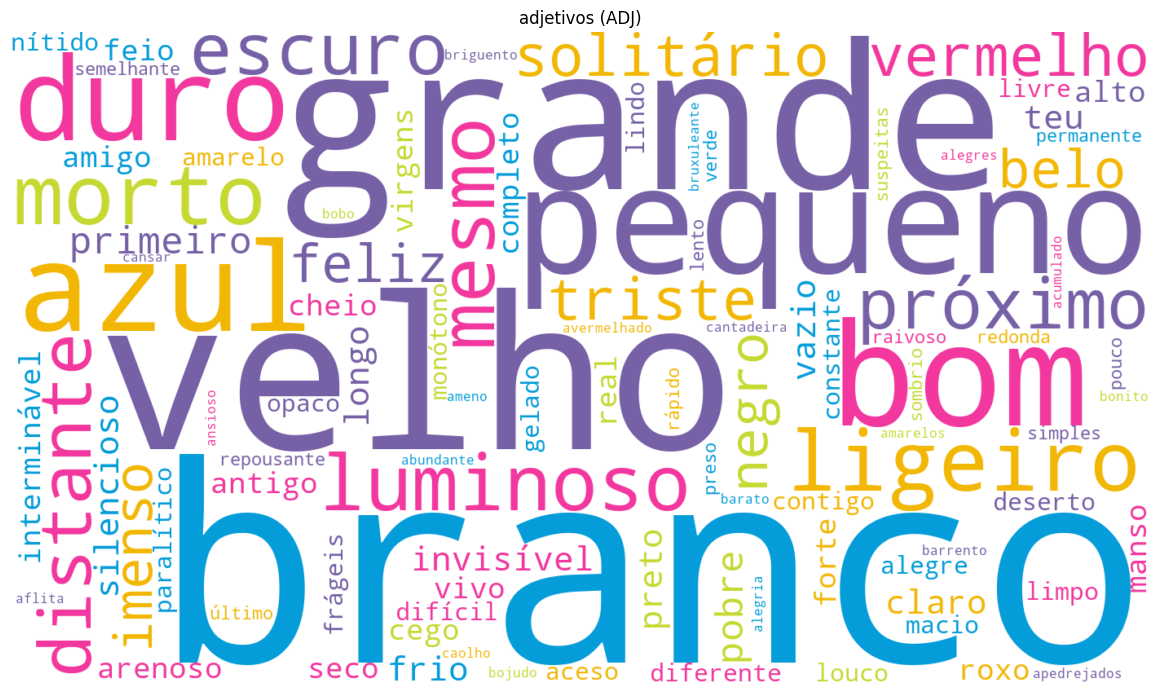


Painel das classes principais


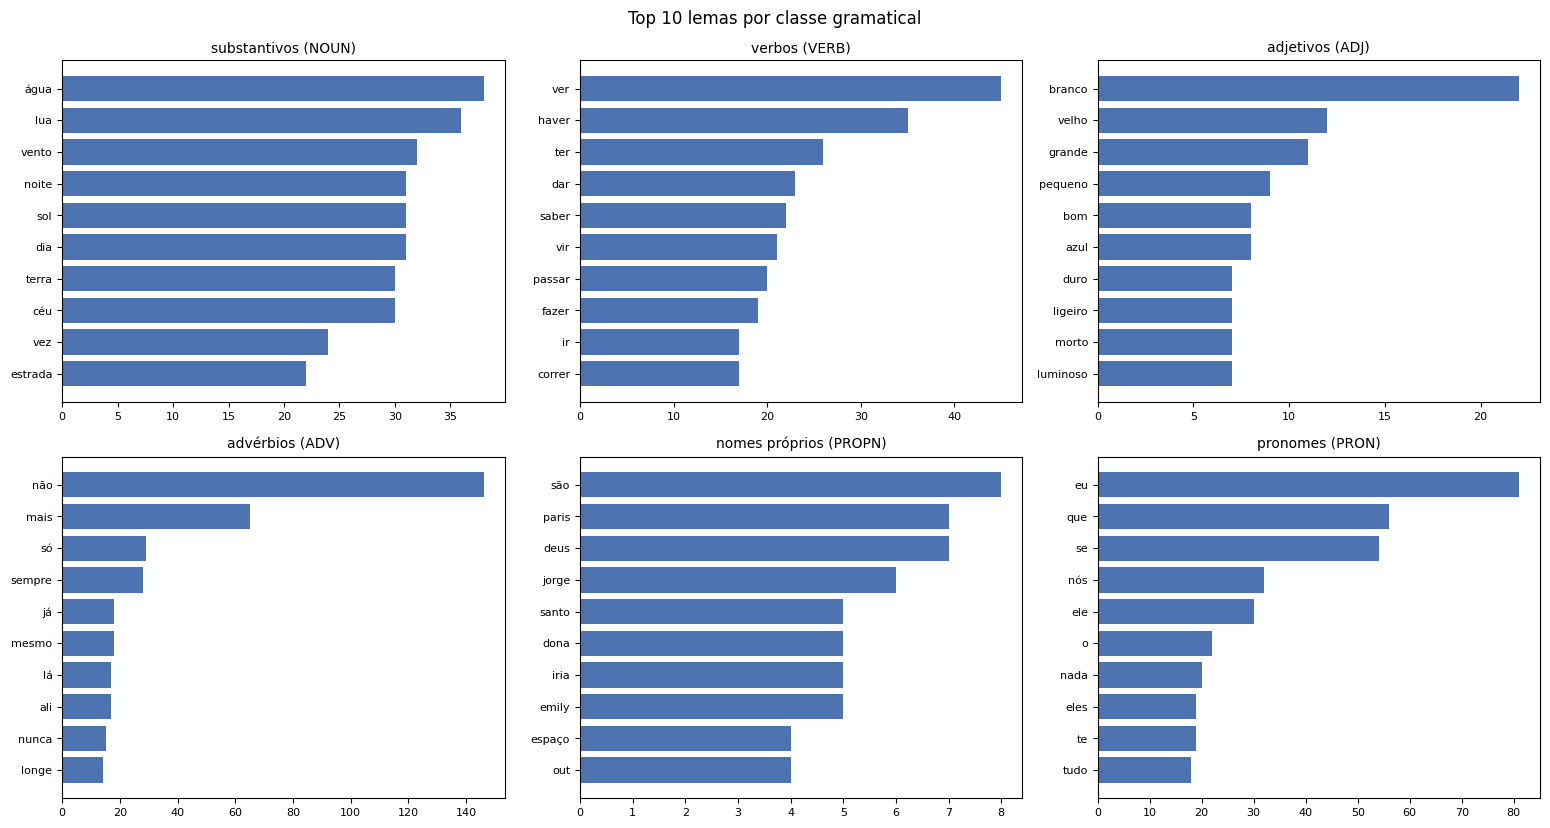


Resumo por classe gramatical:


,classe,nome,palavras,lemas_distintos,mais_frequentes
0,NOUN,substantivos,2427,913,"água (38), lua (36), vento (32), noite (31), sol (31)"
1,VERB,verbos,1485,706,"ver (45), haver (35), ter (26), dar (23), saber (22)"
2,ADP,preposições,1405,48,"de o (317), de (299), em o (192), em (102), a o (92)"
3,DET,determinantes,1269,48,"o (832), meu (82), um (82), seu (43), todo (30)"
4,ADV,advérbios,617,79,"não (146), mais (65), só (29), sempre (28), já (18)"
5,ADJ,adjetivos,496,259,"branco (22), velho (12), grande (11), pequeno (9), bom (8)"
6,PRON,pronomes,465,45,"eu (81), que (56), se (54), nós (32), ele (30)"
7,CCONJ,conjunções coordenativas,440,4,"e (363), ou (31), nem (25), mas (21)"
8,PROPN,nomes próprios,427,335,"são (8), paris (7), deus (7), jorge (6), santo (5)"
9,AUX,verbos auxiliares,232,23,"ser (136), estar (42), ir (18), ter (7), eram (6)"


In [ ]:
if tok is None:
    print("spaCy indisponível (RODAR_SPACY = False, ou spaCy/modelo não instalado): pule esta seção.")
else:
    tabelas_classe, resumo_classes = analise_por_classe(
        tok, SAIDA, TOP, FONTE_NUVEM, USAR_FORMAS, CLASSES_SEM_STOP, CLASSES, MIN_PALAVRAS_CLASSE, CLASSES_EXIBIR,
    )
    print("\nResumo por classe gramatical:")
    display(resumo_classes)

## Observações e limitações

- **Lemas e etiquetas do spaCy são estimativas**, não verdade de referência: em português poético (inversões, elipses, formas arcaicas) o etiquetador erra mais. Lemas de contrações aparecem separados ("em o", "de ela").
- **Poucos dados**: com ≈ 87 palavras por poema, a maioria das palavras tem frequência 1 ou 2. Proporções por classe com poucas ocorrências são instáveis.
- **O ajuste de maiúsculas só vale se o texto tiver `/` entre os versos.** Sem as barras, a primeira letra de cada verso continua em maiúscula e os nomes próprios (PROPN) ficam superestimados.
- **A lista de stopwords da parte 2 é própria**; a da parte 4 é a do spaCy.
- Esta análise **descreve** o corpus; relações entre palavras (grafo de coocorrência, NPMI, comunidades) estão em `grafo_coocorrencia.py` e `grafo_visualizacao_clusters.py`.